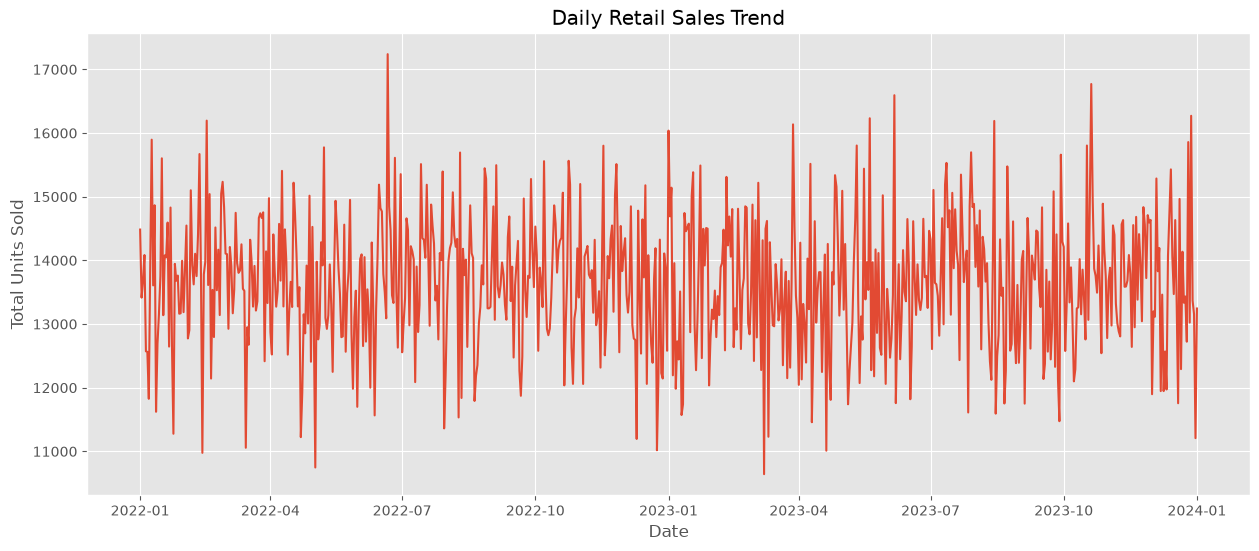

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

df = pd.read_csv("../data/retail_store_inventory.csv")

df["Date"] = pd.to_datetime(df["Date"])

daily_sales = df.groupby("Date")["Units Sold"].sum()

plt.figure(figsize=(15, 6))
plt.plot(daily_sales)

plt.title("Daily Retail Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.show()

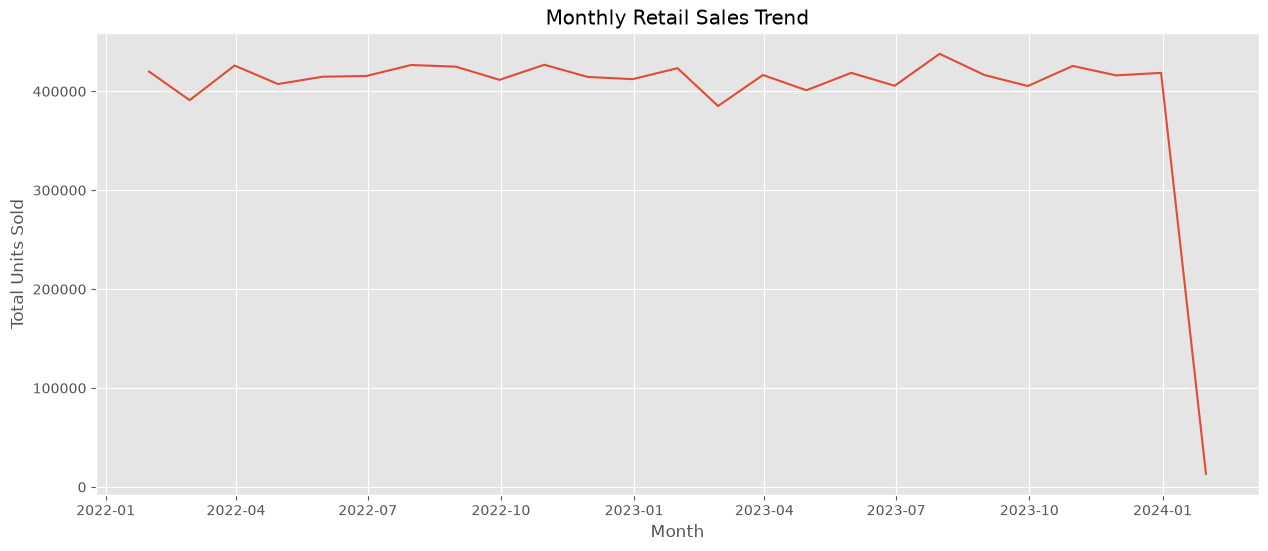

In [2]:
monthly_sales = (
    df.set_index("Date")
    .resample("ME")["Units Sold"]
    .sum()
)

plt.figure(figsize=(15, 6))
plt.plot(monthly_sales)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.show()

In [3]:
yearly_sales = (
    df.set_index("Date")
    .resample("YE")["Units Sold"]
    .sum()
)

print(yearly_sales)

Date
2022-12-31    4991624
2023-12-31    4970714
2024-12-31      13244
Freq: YE-DEC, Name: Units Sold, dtype: int64


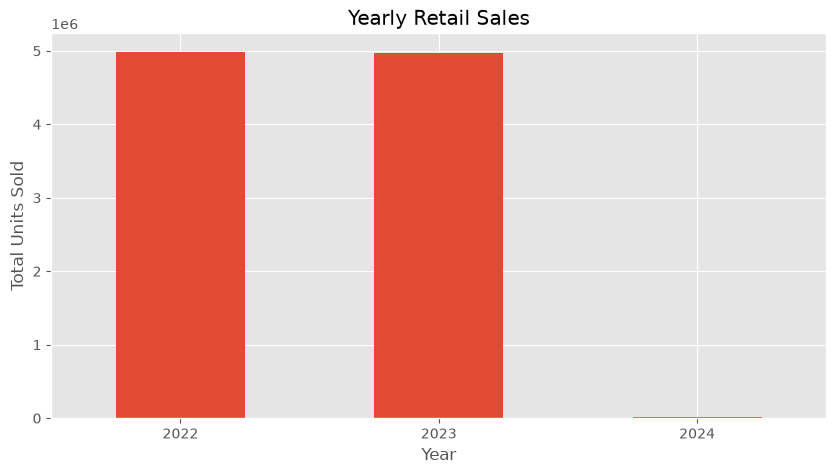

In [4]:
yearly_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Yearly Retail Sales")
plt.xlabel("Year")
plt.ylabel("Total Units Sold")

plt.show()

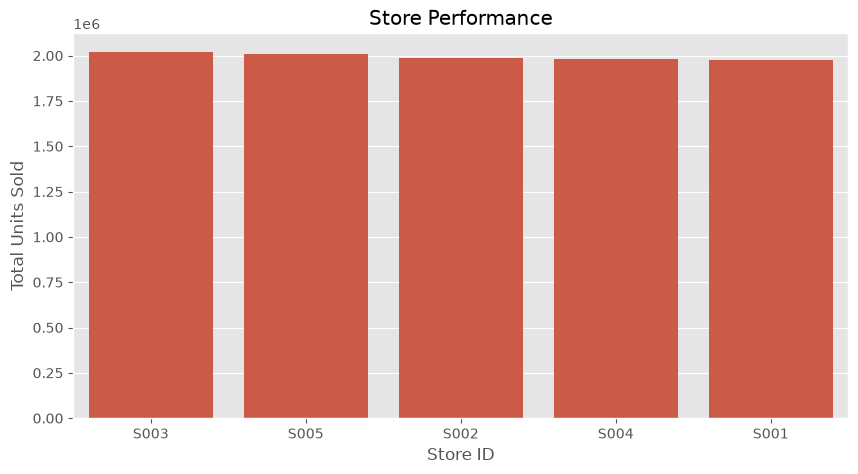

In [5]:
store_sales = (
    df.groupby("Store ID")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(x=store_sales.index, y=store_sales.values)

plt.title("Store Performance")
plt.xlabel("Store ID")
plt.ylabel("Total Units Sold")

plt.show()

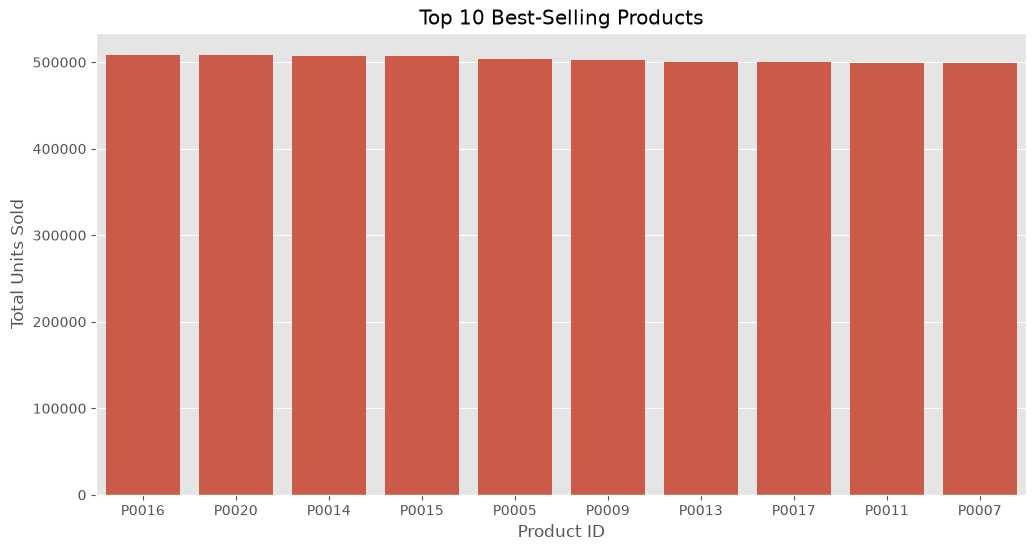

In [6]:
item_sales = (
    df.groupby("Product ID")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
)

top10 = item_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top10.index, y=top10.values)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")

plt.show()

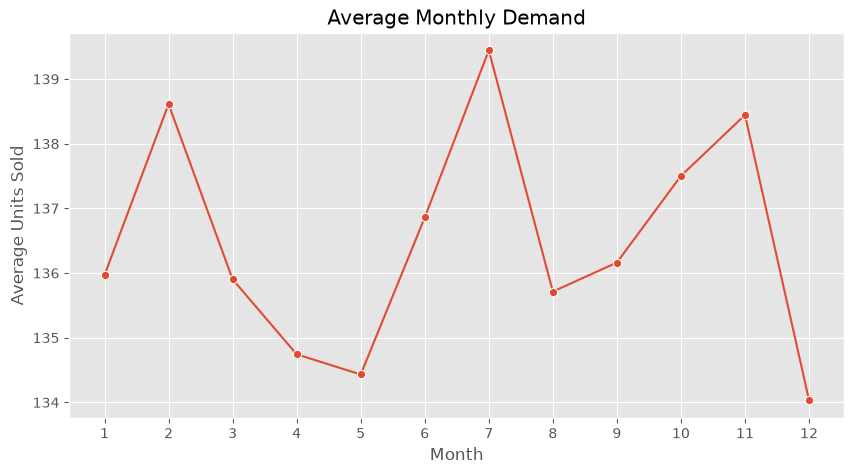

In [7]:
df["Month"] = df["Date"].dt.month

monthly_pattern = (
    df.groupby("Month")["Units Sold"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_pattern.index,
    y=monthly_pattern.values,
    marker="o"
)

plt.title("Average Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.xticks(range(1, 13))

plt.show()

In [8]:
df["DayOfWeek"] = df["Date"].dt.day_name()

dow_sales = (
    df.groupby("DayOfWeek")["Units Sold"]
    .mean()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

dow_sales = dow_sales.reindex(day_order)

print(dow_sales)

DayOfWeek
Monday       135.094667
Tuesday      137.307692
Wednesday    136.615096
Thursday     137.281923
Friday       136.851442
Saturday     135.314476
Sunday       136.809714
Name: Units Sold, dtype: float64


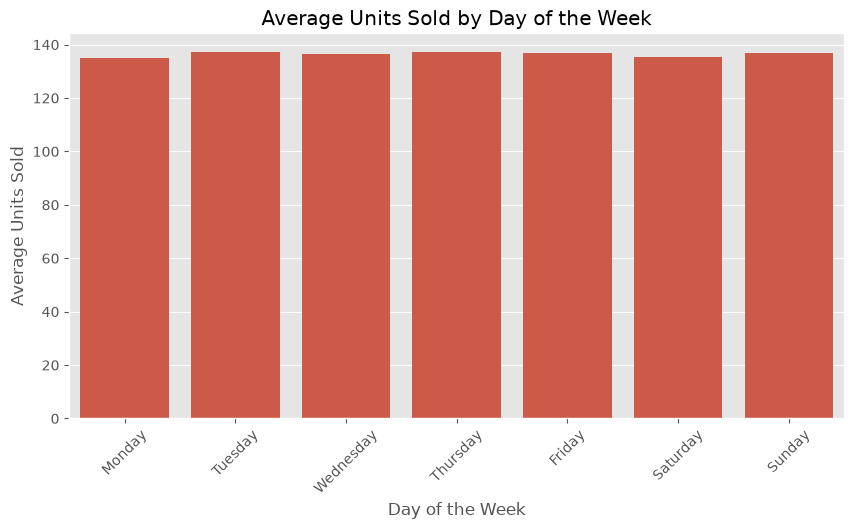

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=dow_sales.index,
    y=dow_sales.values
)

plt.title("Average Units Sold by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=45)

plt.show()

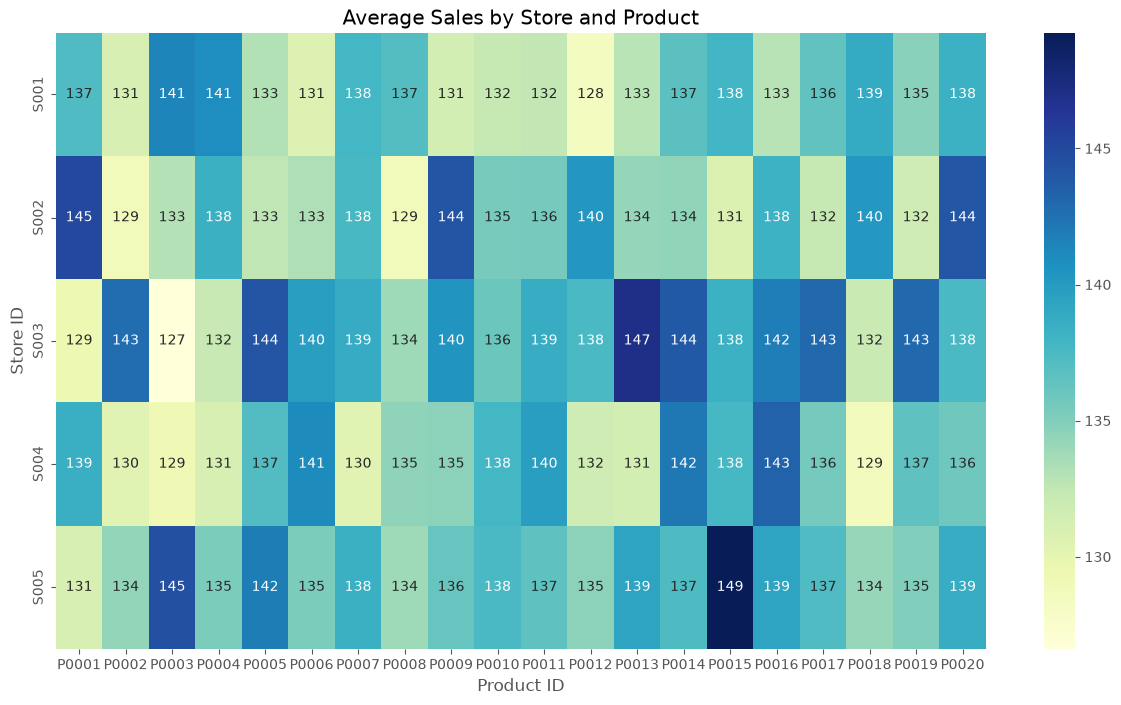

In [10]:
pivot = df.pivot_table(
    values="Units Sold",
    index="Store ID",
    columns="Product ID",
    aggfunc="mean"
)

plt.figure(figsize=(15, 8))

sns.heatmap(
    pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f"
)

plt.title("Average Sales by Store and Product")
plt.xlabel("Product ID")
plt.ylabel("Store ID")

plt.show()